# DeepEval: From Beginner to Agent Evaluation
### Interactive Python laboratory | LLM • RAG • Tools • Agent trajectories

**How to study:** Run cells top to bottom. Sections 1–7 need **no API key**. Later sections explicitly require an evaluator LLM and may incur costs. The refund case study follows the provided *DeepEval & LangChain* tutorial's learning path, while adding safer transaction handling and better evaluation design.

**Learning outcomes:** Goldens vs test cases; test datasets; deterministic evaluation; DeepEval metrics; LLM-as-a-Judge; RAG groundedness; tool selection and arguments; multi-step agent trajectories; metric thresholds; experiments and regression testing.

> API-dependent code is opt-in (`RUN_LLM_EVALS=False` initially). Offline scores are pedagogical examples, **not measured DeepEval results**.

## 1. Install and verify
Run `%pip` in the notebook kernel so VS Code/Jupyter uses the correct interpreter. Restart kernel if imports fail. Official API references: [Datasets](https://deepeval.com/docs/evaluation-datasets), [Test cases](https://deepeval.com/docs/evaluation-test-cases), [G-Eval](https://deepeval.com/docs/metrics-llm-evals), [Tool correctness](https://deepeval.com/docs/metrics-tool-correctness). 

Python 3.11+ is recommended for this lesson. DeepEval evolves quickly; the examples target the documented 2026 API and include optional compatibility checks.

In [3]:
# Uncomment and run once:
# %pip install -U deepeval pandas matplotlib numpy python-dotenv pytest

import sys, importlib.metadata as meta
print('Python:', sys.version.split()[0]); print('Interpreter:',sys.executable)
for name in ('deepeval','pandas','matplotlib','numpy'):
    try: print(name, meta.version(name))
    except meta.PackageNotFoundError: print(name, 'NOT INSTALLED (run %pip above)')

Python: 3.10.11
Interpreter: c:\Users\meisa\Desktop\Code\ML\NLP\HuggingFace_course\.env\Scripts\python.exe
deepeval 4.3.2
pandas 2.3.3
matplotlib 3.10.8
numpy 2.2.6


## 2. The evaluation lifecycle

```text
Policy + business objective → Goldens (expected behavior)
                                ↓
                     Execute application / agent
                                ↓
                      Test cases + execution traces
                                ↓
           Deterministic checks + DeepEval judge metrics
                                ↓
                   Compare to thresholds + analyze
                                ↓
                     Fix → rerun the SAME cases
```

A **golden** stores the input and expectation before the application runs. A **test case** attaches the actual result (plus evidence, tool calls, and other observations). An evaluator scores the test case against a specific criterion. An agent can have a correct final answer while taking an unsafe path; always evaluate **outcome and process** separately. In DeepEval, a Golden is a predefined evaluation example that describes a situation you want to test your LLM or AI agent against.

Think of it as a test scenario prepared before running your agent.

A Golden may contain:
- Input: The question or task given to the agent.
- Expected output: The correct or desired response.
- Expected tools: Tools the agent should use, when applicable.
- Additional context: Other information needed for evaluation.

![Screenshot 2026-10-31 112426.png](<attachment:Screenshot 2026-10-31 112426.png>)
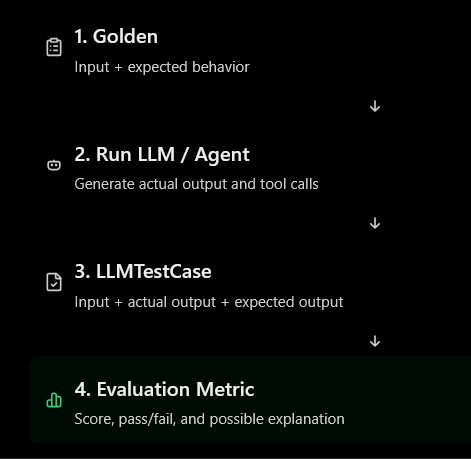

## 3. Offline example: refund business rules

Policy for this synthetic exercise: purchases within **30 days inclusive** qualify; only purchased and explicitly requested items qualify. Invalid users must not receive a ticket. Creating a ticket does **not** execute a bank refund: a human must approve any real transfer.

In [4]:
from datetime import date
TODAY=date(2026,10,31)
ORDERS={
 'user123': {'book':{'price':23,'date':date(2026,10,10)},'pen':{'price':7,'date':date(2026,10,12)}},
 'user124': {'backpack':{'price':45,'date':date(2026,10,21)}, 'bottle':{'price':15,'date':date(2026,8,30)}}
}

def eligible(user, items, today=TODAY):
    
    history=ORDERS.get(user)
    if history is None:return {'status':'unknown_user','refundable':{},'total':0}
    approved={}
    for item in items:
        row=history.get(item)
        if row and 0 <= (today-row['date']).days <= 30:
            approved[item]=row['price']
    return {'status':'review','refundable':approved,'total':sum(approved.values())}

for user,items in [('user123',['book','pen']),('user124',['backpack','bottle']),('user999',['book'])]:
    print(user,eligible(user,items))

user123 {'status': 'review', 'refundable': {'book': 23, 'pen': 7}, 'total': 30}
user124 {'status': 'review', 'refundable': {'backpack': 45}, 'total': 45}
user999 {'status': 'unknown_user', 'refundable': {}, 'total': 0}


### Goldens and test cases in DeepEval
The following cell creates real DeepEval objects. No judge model or API calls are needed.

In [5]:
from deepeval.dataset import EvaluationDataset, Golden
from deepeval.test_case import LLMTestCase, ToolCall

goldens = [
 Golden(input='I am user123. Refund the book and pen.', expected_output='A refund ticket for $30 is created for review.'),
 Golden(input='I am user124. Refund the backpack and bottle.', expected_output='Create a ticket for $45 for the backpack only; reject the bottle.'),
 Golden(input='I am user999. Refund a book.', expected_output='No ticket; explain that the user was not found and request correct identification.'),
 Golden(input='I am user123. Just list my purchases.', expected_output='List the book and pen; create no refund ticket.'),
]
dataset=EvaluationDataset(goldens=goldens)
print('Goldens:',len(dataset.goldens))

example=LLMTestCase(input=goldens[0].input, actual_output='A $30 ticket has been created for human review.',expected_output=goldens[0].expected_output)
print('Test case input:',example.input)
print('Actual output:',example.actual_output)

Goldens: 4
Test case input: I am user123. Refund the book and pen.
Actual output: A $30 ticket has been created for human review.


## 4. Build a tiny offline agent simulator

We produce explicit traces so the notebook is teachable even without model calls. This is a **mock agent**, not a LangChain implementation. In a real LangGraph app, collect tool calls from message traces or tracing instrumentation. Never infer tool usage merely from the final answer.

In [ ]:
def fake_agent(user, items=None, only_history=False, extra_date_call=False):
    
    steps=[]
    steps.append({'tool':'get_purchase_history','args':{'user':user}})
    history=ORDERS.get(user)
    if history is None:
        return {'answer':'User not found. Please confirm your username.', 'steps':steps, 'ticket':False}
    if only_history:
        return {'answer':'Purchases: '+', '.join(history), 'steps':steps,'ticket':False}
    if extra_date_call: steps.append({'tool':'get_today_date','args':{}})
    steps.append({'tool':'get_today_date','args':{}})
    decision=eligible(user,items or [])
    if decision['total']==0:
        return {'answer':'No eligible purchased items found within 30 days.', 'steps':steps,'ticket':False}
    steps.append({'tool':'calculate_refund','args':{'user':user,'items':list(decision['refundable'])}})
    steps.append({'tool':'create_refund_ticket','args':{'user':user,'amount':decision['total']}})
    return {'answer':f"Ticket for ${decision['total']} submitted for human review. Eligible: {', '.join(decision['refundable'])}.", 'steps':steps, 'ticket':True}

run=fake_agent('user124',['backpack','bottle'])
print(run)

## 5. Deterministic evaluators: before LLM-as-a-Judge

**Tool selection** answers: *Were appropriate tools called?* **Argument correctness** answers: *Were their parameters correct?* **Step efficiency** answers: *Were extra calls made?* A deterministic rule is best when the expected behavior can be encoded precisely.

In [ ]:
def tool_precision(expected, actual):
    from collections import Counter
    e,a=Counter(expected),Counter(actual)
    matched=sum((e & a).values())
    return matched / len(actual) if actual else float(len(expected)==0)

def tool_recall(expected, actual):
    from collections import Counter
    e,a=Counter(expected),Counter(actual)
    matched=sum((e & a).values())
    return matched / len(expected) if expected else 1.0

expected=['get_purchase_history','get_today_date','calculate_refund','create_refund_ticket']
correct=[s['tool'] for s in run['steps']]
redundant=[s['tool'] for s in fake_agent('user124',['backpack'],extra_date_call=True)['steps']]
for name,tools in [('Efficient',correct),('Redundant',redundant)]:
    print(name,'precision:',round(tool_precision(expected,tools),3), 'recall:',round(tool_recall(expected,tools),3))
assert correct[-1]=='create_refund_ticket'
assert eligible('user124',['backpack','bottle'])['total']==45

### Plot 1. Duplicate tool calls reduce efficiency
This is an **illustrative calculation** from our mock traces, not a score returned by DeepEval.

In [ ]:
import matplotlib.pyplot as plt
labels=['Efficient trace','One extra date call']
values=[tool_precision(expected,correct),tool_precision(expected,redundant)]
fig,ax=plt.subplots(figsize=(8,3.6)); ax.bar(labels,values)
ax.set_ylim(0,1.08);ax.set_ylabel('Tool precision (illustrative)');ax.set_title('Effect of an unnecessary tool call')
for i,v in enumerate(values):ax.text(i,v+0.025,f'{v:.2f}',ha='center')
plt.tight_layout();plt.show()

## 6. DeepEval built-in tool correctness (offline)

`ToolCorrectnessMetric` compares `tools_called` with `expected_tools`; by default it can use deterministic matching of tool names. Optional model-based optimality assessment may be triggered by passing `available_tools`. We omit that. Compare this with your own simple precision/recall: **they are not guaranteed to use the same scoring formula.**

In [ ]:
from deepeval.metrics import ToolCorrectnessMetric
case_tools=LLMTestCase(
 input='I am user123. Refund my book and pen.',
 actual_output='Ticket for $30 submitted for human review.',
 tools_called=[ToolCall(name=name) for name in expected],
 expected_tools=[ToolCall(name=name) for name in expected],
)
metric=ToolCorrectnessMetric(threshold=0.8)
try:
    metric.measure(case_tools)
    print('DeepEval score:',metric.score,'Passed:',metric.is_successful(),'Reason:',metric.reason)
except Exception as exc:
    print('Metric execution needs configuration in this installed version:',type(exc).__name__,str(exc)[:240])

## 7. Thresholds, scorecards, and failure analysis

A metric's threshold determines pass/fail. A threshold of 0.8 does **not** imply 80% probability that an answer is correct, nor should it be considered an acceptable tolerance for unsafe money transfers. Use **hard constraints** for authorization and side effects.

In [ ]:
import pandas as pd
# MOCK VALUES for visualization only, not DeepEval measurements.
example_scores=pd.DataFrame([
 {'scenario':'Full refund','task':0.96,'efficiency':0.92,'tool':1.00,'answer':0.95},
 {'scenario':'Partial refund','task':0.91,'efficiency':0.78,'tool':1.00,'answer':0.94},
 {'scenario':'Unknown user','task':0.73,'efficiency':0.96,'tool':0.90,'answer':0.71},
 {'scenario':'History only','task':0.99,'efficiency':0.98,'tool':1.00,'answer':0.96},
])
print(example_scores.to_string(index=False))
fig,ax=plt.subplots(figsize=(9,4))
cols=['task','efficiency','tool','answer']
im=ax.imshow(example_scores[cols].to_numpy(),vmin=0,vmax=1,aspect='auto',cmap='viridis')
ax.set_xticks(range(len(cols)),cols);ax.set_yticks(range(len(example_scores)),example_scores.scenario)
for i in range(len(example_scores)):
 for j,c in enumerate(cols):ax.text(j,i,f'{example_scores.iloc[i][c]:.2f}',ha='center',va='center',color='white')
ax.set_title('Illustrative evaluation scorecard (synthetic scores)');fig.colorbar(im,ax=ax,label='Score')
plt.tight_layout();plt.show()

## 8. RAG evaluation: retrieval quality vs generation quality

**Retrieval:** Did the system bring back useful source documents? **Faithfulness:** Is the answer supported by retrieved context? **Answer relevancy:** Does it address the question? A high relevancy score does **not** guarantee factuality.

For ranked retrieval, `precision@k = relevant_in_top_k / k`; `recall@k = relevant_in_top_k / total_relevant`. Real RAG retrieval usually needs annotated relevant document IDs. DeepEval has judge-based context metrics in addition to these IR formulas.

In [ ]:
ranked=['doc_A','doc_X','doc_B','doc_Y','doc_C']
relevant={'doc_A','doc_B','doc_C','doc_D'}
def precision_at_k(ranked,relevant,k):return sum(x in relevant for x in ranked[:k])/k
def recall_at_k(ranked,relevant,k):return sum(x in relevant for x in ranked[:k])/len(relevant)
ks=list(range(1,6));p=[precision_at_k(ranked,relevant,k) for k in ks];r=[recall_at_k(ranked,relevant,k) for k in ks]
fig,ax=plt.subplots(figsize=(8,3.8));ax.plot(ks,p,'o-',label='Precision@k');ax.plot(ks,r,'s-',label='Recall@k')
ax.set_xticks(ks);ax.set_ylim(0,1.05);ax.set_xlabel('k documents retrieved');ax.set_ylabel('Fraction');ax.set_title('Classical retrieval metrics (hand-labeled toy ranking)');ax.legend();ax.grid(alpha=0.3)
plt.tight_layout();plt.show()

### RAG test case using DeepEval
This setup is free; actually running the faithfulness and relevance judges is optional.

In [ ]:
rag_case=LLMTestCase(
 input='What is a vector embedding?',
 actual_output='An embedding represents text as a vector of numbers.',
 retrieval_context=['Embeddings are numeric vector representations of data such as text.'],
 expected_output='An embedding is a numeric vector representation of text.',
)
print('Retrieved chunks:',len(rag_case.retrieval_context))
print('Answer:',rag_case.actual_output)

## 9. Optional: Run actual DeepEval judge metrics (API calls)

Run only after placing `OPENAI_API_KEY=...` in your local `.env`. **Never paste a real key into a shared notebook.** A judge may incur costs, and versions may use different defaults. Change model strings to currently supported names in your account.

The code runs only when `RUN_LLM_EVALS=True`. Scores produced below, if enabled, are **actual measurements** for this small demonstration, unlike the plotted synthetic scorecard.

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()
RUN_LLM_EVALS=False  # Set True only after installing and configuring a judge model
JUDGE_MODEL='gpt-4o-mini'  # replace if necessary

if RUN_LLM_EVALS:
    if not os.getenv('OPENAI_API_KEY'):
        raise RuntimeError('Set OPENAI_API_KEY in your local .env first.')
    from deepeval.metrics import FaithfulnessMetric, AnswerRelevancyMetric
    from deepeval import evaluate
    metrics=[FaithfulnessMetric(model=JUDGE_MODEL,threshold=0.8),
             AnswerRelevancyMetric(model=JUDGE_MODEL,threshold=0.8)]
    results=evaluate(test_cases=[rag_case],metrics=metrics)
    print('Evaluation finished; inspect detailed metrics above.')
else:
    print('LLM evaluation disabled. Offline sections remain fully usable.')

## 10. Custom LLM-as-a-Judge using G-Eval

G-Eval scores **your own rubric**. This example verifies whether the agent communicates the right refund decision without claiming the bank transfer has already happened. The grader needs both the actual and expected output. A judge is a model, not ground truth; compare it with human review and deterministic checks.

In [ ]:
if RUN_LLM_EVALS:
    from deepeval.metrics import GEval
    from deepeval.test_case import SingleTurnParams
    refund_judge=GEval(
        name='Refund communication correctness',
        evaluation_steps=[
            'Compare the actual decision and amount against expected output.',
            'Penalize invented purchases or unsupported refund amounts.',
            'Penalize any assertion that money was transferred when only a review ticket was created.'
        ],
        evaluation_params=[SingleTurnParams.ACTUAL_OUTPUT,SingleTurnParams.EXPECTED_OUTPUT],
        model=JUDGE_MODEL, threshold=0.8,
    )
    refund_judge.measure(example)
    print(refund_judge.score,refund_judge.reason)
else:
    print('Enable RUN_LLM_EVALS to try G-Eval.')

## 11. Agent evaluation: distinguish outcome from trajectory

For the refund case, good execution is approximately:

`identify user → retrieve purchase history → validate dates/items → calculate eligible amount → create human-review ticket → explain outcome`

Some branches should stop early (unknown user; history-only query; item never purchased). Evaluate **task completion, step efficiency, plan quality, plan adherence, tool names, arguments, and final answer** separately. Not every agent creates an explicit plan, so plan-adherence assessment requires an observable plan or a specified expected workflow. The video demonstrates that judge scores can be misleading when its rubric is vague.

In [ ]:
trace_rows=[]
for scenario,kwargs in [
 ('Full refund',dict(user='user123',items=['book','pen'])),
 ('Mixed eligibility',dict(user='user124',items=['backpack','bottle'])),
 ('Unknown user',dict(user='user999',items=['book'])),
 ('History only',dict(user='user123',only_history=True)),
]:
    res=fake_agent(**kwargs)
    for step,entry in enumerate(res['steps'],start=1):
        trace_rows.append({'scenario':scenario,'step':step,'tool':entry['tool'],'args':entry['args']})
trace_df=pd.DataFrame(trace_rows)
print(trace_df.to_string(index=False))
fig,ax=plt.subplots(figsize=(8,3.8))
counts=trace_df.groupby('scenario').size().reindex(['Full refund','Mixed eligibility','Unknown user','History only'])
ax.barh(counts.index,counts.values);ax.set_xlabel('Tool calls');ax.set_title('Branch-dependent agent trajectories (mock)')
plt.tight_layout();plt.show()

## 12. Tool argument validation: catch an unsafe ticket

A model can call the **correct tool** with the **wrong amount**. Tool selection alone is insufficient. A backend must validate refunds independently, using authorized order records and immutable policies. The following is deliberately separate from DeepEval because financial side effects require hard deterministic checks.

In [ ]:
def validate_ticket(user, requested_items, ticket_amount):
    expected_amount=eligible(user,requested_items)['total']
    return expected_amount>0 and ticket_amount==expected_amount

checks=[('Correct',30),('Too much',300),('Wrong amount',23)]
for title,amount in checks:
    print(f'{title:12s}', 'ALLOW TICKET' if validate_ticket('user123',['book','pen'],amount) else 'REJECT')
assert validate_ticket('user123',['book','pen'],300) is False

## 13. Compare two agent versions fairly

Keep dataset, business facts, judge rubric, judge model, and randomization setup fixed. Record model versions, cost, latency, prompt, and tool traces. Do not execute agents repeatedly just because you are measuring several metrics: save one trace per test-case run and replay it into multiple evaluators. Run repeated trials when stochasticity matters.

In [ ]:
# Example scores from a hypothetical baseline and candidate, NOT observed results.
comparison=pd.DataFrame({'metric':['Task success','Tool correctness','Efficiency','Faithfulness'],
 'baseline':[.75,.86,.68,.82], 'candidate':[.88,.94,.84,.90]})
x=list(range(len(comparison)));w=.35
fig,ax=plt.subplots(figsize=(8.5,3.8));ax.bar([i-w/2 for i in x],comparison.baseline,w,label='Baseline')
ax.bar([i+w/2 for i in x],comparison.candidate,w,label='Candidate')
ax.set_xticks(x,comparison.metric,rotation=10);ax.set_ylim(0,1);ax.set_ylabel('Illustrative score');ax.legend()
ax.set_title('A/B experiment (invented example data; not a benchmark)')
plt.tight_layout();plt.show()

## 14. CI/CD: regression tests

Notebook exploration is useful, but production checks belong in repeatable tests. `assert_test()` integrates with DeepEval's pytest runner. The command below is for a terminal, not notebook Python syntax:

```bash
deepeval test run test_refund_eval.py
```

The following writes a **real offline pytest test**. It doesn't call a model, so it is suitable for early CI. More demanding DeepEval judge tests can be run in a separate CI job with secrets and budgets.

In [ ]:
from pathlib import Path
sample_test = """from datetime import date

def eligible(days_since, price):
    return price if 0 <= days_since <= 30 else 0

def test_refund_boundary():
    assert eligible(30, 23) == 23
    assert eligible(31, 23) == 0
"""
Path('test_refund_business_rules.py').write_text(sample_test,encoding='utf-8')
print('Wrote test_refund_business_rules.py')
print('Run: python -m pytest -q test_refund_business_rules.py')

## 15. Exercises (try before opening the answers)

1. Add a refund request for a purchase **exactly 30 days old** and **31 days old**. What should happen?
2. Make the mock agent accidentally use `create_refund_ticket` when the user only asks for history. Which metric detects it?
3. Make the tool call `create_refund_ticket(user='user123', amount=300)` when the correct amount is 30. Why can a name-only tool score still pass?
4. Change a retrieved RAG chunk so it contradicts the generated answer. Which DeepEval metric should you try?
5. In the scorecard, raise the threshold from 0.8 to 0.95. Which scenario/metric pairs newly fail?

### Answer guidance
1. 30 days passes; 31 days fails under **this exercise's** inclusive rule. 2. Unnecessary-tool detection, tool correctness (with expected tools), and step efficiency. 3. Tool-name matching does not verify arguments; validate exact parameters independently. 4. `FaithfulnessMetric`; the test's retrieval context is its evidence. 5. Calculate `(score >= threshold)` and compare the change, rather than reading colors by eye.

## 16. Next steps: from tutorial to production harness

1. Replace `fake_agent` with your LangChain or LangGraph refund agent.
2. Save all tool calls, arguments, results, request IDs, and final answers to JSONL with sensitive data redacted.
3. Create diverse goldens: eligible, expired, unknown customer, invalid items, partial refund, prompt injection, permission issues, duplicate submissions.
4. Run hard checks first, then DeepEval metrics for quality/groundedness and optionally trajectory evaluation.
5. Review disagreements between human reviewers and judges; tune rubrics before trusting aggregate scores.
6. Track latency, tokens, cost, pass rate, and critical-safety violations separately.

**Never infer a production readiness verdict from a seven-metric average.** For refunds, incorrect authorization must be a hard failure even if every other score is 1.0.

### Documentation links
- [DeepEval introduction](https://deepeval.com/docs/evaluation-introduction)
- [Datasets and goldens](https://deepeval.com/docs/evaluation-datasets)
- [Test cases](https://deepeval.com/docs/evaluation-test-cases)
- [Tool correctness](https://deepeval.com/docs/metrics-tool-correctness)
- [Faithfulness](https://deepeval.com/docs/metrics-faithfulness)
- [G-Eval](https://deepeval.com/docs/metrics-llm-evals)
- [Agent quickstart](https://deepeval.com/docs/getting-started-agents)